# Order Items Exploratory Data Analysis (EDA)

## Objective
Analyze the Olist order items dataset to understand order composition, product distribution, seller activity, pricing, and freight values.

## Dataset
`olist_order_items_dataset.csv`

In [74]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('olist_order_items_dataset.csv')

In [4]:
df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [5]:
df.shape

(112650, 7)

In [6]:
df.dtypes

order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

In [7]:
df.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')

In [8]:
print("Total Rows : ",df.shape[0])
print("Total Columns : ",df.shape[1])

print("Unique Orders : ",df['order_id'].nunique())
print("Unique Products : ",df['product_id'].nunique())
print("Unique Sellers : ",df['seller_id'].nunique())

Total Rows :  112650
Total Columns :  7
Unique Orders :  98666
Unique Products :  32951
Unique Sellers :  3095


### Missing Values Analysis

The dataset contains no missing values across all seven columns. Therefore, no missing-value handling is required at this stage.

In [10]:
print("Missing Values : " , df.isnull().sum())

Missing Values :  order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


### Duplicate Records Analysis

The dataset contains 0 fully duplicated rows. Each row represents a distinct order item record.

In [ ]:
print("Duplicate Values: ",df.duplicated().sum())

Duplicate :  0


In [13]:
print("Price Analysis : ",df['price'].describe())

Price Analysis :  count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64


In [14]:
(df['price'] <= 0).sum()

np.int64(0)

### Price Outliers Analysis

Using the IQR method, statistical outliers were identified in the price column.

The lower bound is **-102.60**, and the upper bound is **277.40**. Therefore, prices above 277.40 are considered statistical outliers.

No lower outliers were detected because the minimum price (0.85) is above the lower bound (-102.60).

These values are not necessarily incorrect, as they may represent high-value products. They should be investigated before making any decision to remove them.

In [75]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3-Q1 

lower_bound = Q1-(1.5*IQR )
upper_bound = Q3+(1.5*IQR )

outliers = df[
    (df['price'] < lower_bound) |
    (df['price'] > upper_bound)
]
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Outliers:", outliers.shape[0])

Q1: 39.9
Q3: 134.9
IQR: 95.0
Lower Bound: -102.6
Upper Bound: 277.4
Outliers: 8427


### Price Distribution Visualization

The histogram shows a highly right-skewed distribution.

Most order items have relatively low prices, while a small number of items have significantly higher prices, creating a long right tail.

This observation is consistent with the mean (120.65) being greater than the median (74.99).

High prices should be investigated rather than automatically treated as incorrect values.

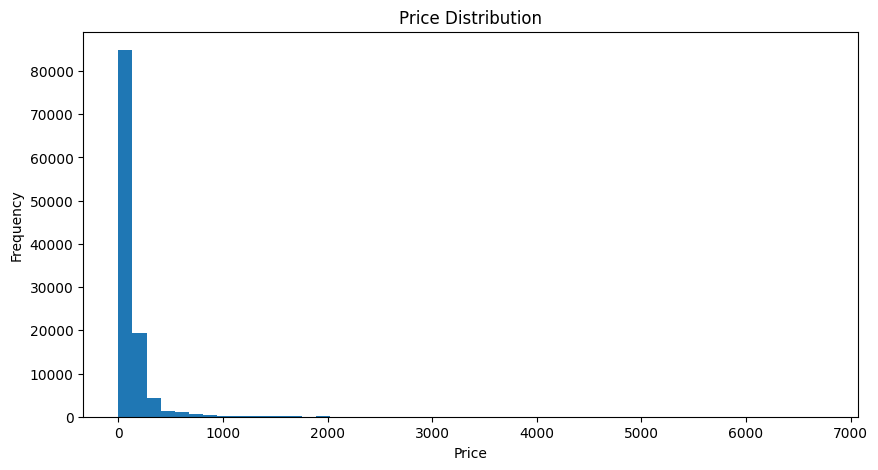

In [24]:
plt.figure(figsize=(10, 5))
plt.hist(df['price'], bins=50)
plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

### Freight Value Outliers Analysis

Using the IQR method, statistical outliers were identified in the freight value column.

The lower bound is **0.975**, and the upper bound is **33.255**. Therefore, freight values above 33.255 are considered upper statistical outliers, while values below 0.975 are considered lower outliers.

Some records with zero freight value are classified as lower outliers. However, zero shipping costs may represent free shipping rather than invalid data.

High shipping costs should be investigated before considering them errors or removing them.

In [25]:
df['freight_value'].describe()

count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64

In [27]:
(df['freight_value'] < 0).sum()

np.int64(0)

In [28]:
(df['freight_value'] == 0).sum()

np.int64(383)

In [26]:
Q1 = df['freight_value'].quantile(0.25)
Q3 = df['freight_value'].quantile(0.75)

IQR = Q3-Q1 

lower_bound = Q1-(1.5*IQR) 
upper_bound = Q3+(1.5*IQR )

outliers = df[
    (df['freight_value'] < lower_bound) |
    (df['freight_value'] > upper_bound)
]
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Outliers:", outliers.shape[0])

Q1: 13.08
Q3: 21.15
IQR: 8.069999999999999
Lower Bound: 0.9750000000000032
Upper Bound: 25.184999999999995
Outliers: 19658


### Freight Value Distribution Visualization

The histogram shows a right-skewed distribution. Most shipping costs are concentrated at relatively low values, while a smaller number of records have significantly higher shipping costs.

The mean (19.99) is greater than the median (16.26), supporting the right-skewness observation.

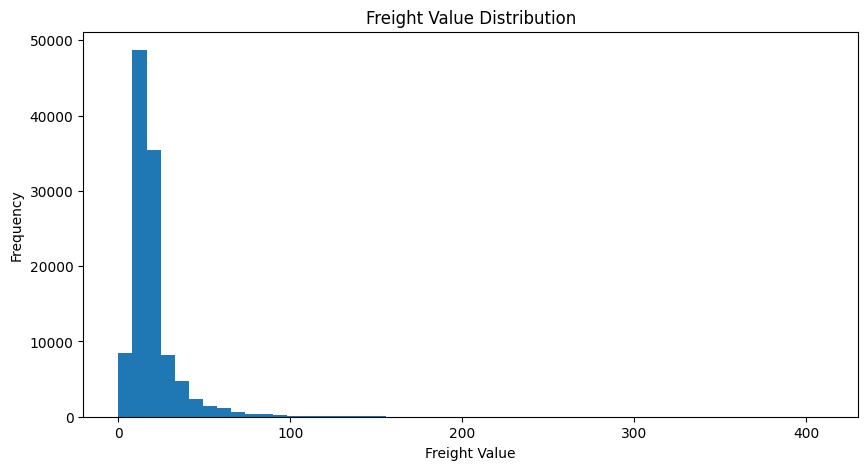

In [29]:
plt.figure(figsize=(10, 5))
plt.hist(df['freight_value'], bins=50)
plt.title('Freight Value Distribution')
plt.xlabel('Freight Value')
plt.ylabel('Frequency')
plt.show()

In [56]:
df.groupby('order_id')['order_item_id'].count().value_counts()

order_item_id
1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
10        8
12        5
11        4
9         3
20        2
15        2
14        2
13        1
21        1
Name: count, dtype: int64

In [57]:
df.groupby(['order_id','product_id'])['order_item_id'].count().value_counts()

order_item_id
1     95337
2      5382
3       953
4       390
6       172
5       168
10        5
7         4
8         2
20        2
12        2
15        2
14        2
9         2
13        1
11        1
Name: count, dtype: int64

In [58]:
product_repetition = df.groupby(
    ['order_id', 'product_id']
)['order_item_id'].count()

In [59]:
repeated_products = product_repetition[product_repetition > 1]

print(repeated_products)
print("Repeated groups:", repeated_products.shape[0])

order_id                          product_id                      
0008288aa423d2a3f00fcb17cd7d8719  368c6c730842d78016ad823897a372db    2
00143d0f86d6fbd9f9b38ab440ac16f5  e95ee6822b66ac6058e2e4aff656071a    3
001ab0a7578dd66cd4b0a71f5b6e1e41  0b0172eb0fd18479d29c3bc122c058c2    3
001d8f0e34a38c37f7dba2a37d4eba8b  e67307ff0f15ade43fcb6e670be7a74c    2
002c9def9c9b951b1bec6d50753c9891  2d9ff06c8870a518f5f6909774e140fb    2
                                                                     ..
ffd84ab39cd5e873d8dba24342e65c01  fcf50ee5ad1f1a48671052487d2b0bff    2
ffe4b41e99d39f0b837a239110260530  e97df839917a6e93404867b1d0319bfc    2
ffecd5a79a0084f6a592288c67e3c298  50fd2b788dc166edd20512370dac54df    3
fff8287bbae429a99bb7e8c21d151c41  bee2e070c39f3dd2f6883a17a5f0da45    2
fffb9224b6fc7c43ebb0904318b10b5f  43423cdffde7fda63d0414ed38c11a73    4
Name: order_item_id, Length: 7088, dtype: int64
Repeated groups: 7088


### Repeated Products Within Orders

The analysis identified 7,088 `(order_id, product_id)` combinations where the same product appears more than once within an order.

These repeated combinations affect 6,968 distinct orders.

This indicates that some orders contain multiple repeated products. These cases should be investigated rather than automatically treated as data errors.

In [60]:
repeated_products.index.get_level_values(0).nunique()

6968

In [61]:
df['seller_id'].nunique()

3095

In [62]:
df.groupby('seller_id')['order_item_id'].count().sort_values(ascending=False)

seller_id
6560211a19b47992c3666cc44a7e94c0    2033
4a3ca9315b744ce9f8e9374361493884    1987
1f50f920176fa81dab994f9023523100    1931
cc419e0650a3c5ba77189a1882b7556a    1775
da8622b14eb17ae2831f4ac5b9dab84a    1551
                                    ... 
cf281cf8b7affbdfe751b29cc85580e1       1
d1e2fe627180431ffda076abb303c56f       1
d1aa1ec0839dcab73a6161130eb1f94a       1
d1a5cc844736958c11b8efab9a2b4c87       1
d1a1b40ec554c593a1a99366746289dd       1
Name: order_item_id, Length: 3095, dtype: int64

### Seller Activity Distribution

The dataset contains 3,095 unique sellers.

The average number of order items per seller is 36.40, while the median is only 8.

The maximum number of order items for a single seller is 2,033, compared to a minimum of 1.

The large difference between the mean and median, along with the high standard deviation (119.19), indicates a highly right-skewed distribution.

This suggests that seller activity is not evenly distributed, as a relatively small number of sellers account for a large number of order items.

In [63]:
Most_seller = df.groupby('seller_id')['order_item_id'].count().sort_values(ascending=False)
Most_seller.head(10)

seller_id
6560211a19b47992c3666cc44a7e94c0    2033
4a3ca9315b744ce9f8e9374361493884    1987
1f50f920176fa81dab994f9023523100    1931
cc419e0650a3c5ba77189a1882b7556a    1775
da8622b14eb17ae2831f4ac5b9dab84a    1551
955fee9216a65b617aa5c0531780ce60    1499
1025f0e2d44d7041d6cf58b6550e0bfa    1428
7c67e1448b00f6e969d365cea6b010ab    1364
ea8482cd71df3c1969d7b9473ff13abc    1203
7a67c85e85bb2ce8582c35f2203ad736    1171
Name: order_item_id, dtype: int64

In [64]:
Most_seller.describe()

count    3095.000000
mean       36.397415
std       119.193461
min         1.000000
25%         2.000000
50%         8.000000
75%        24.000000
max      2033.000000
Name: order_item_id, dtype: float64

### Seller Activity Distribution Visualization

The histogram shows a highly right-skewed distribution.

Most sellers have a relatively small number of order items, while a small number of sellers have significantly higher activity.

This confirms the difference between the mean (36.40) and median (8), indicating that seller activity is not evenly distributed.

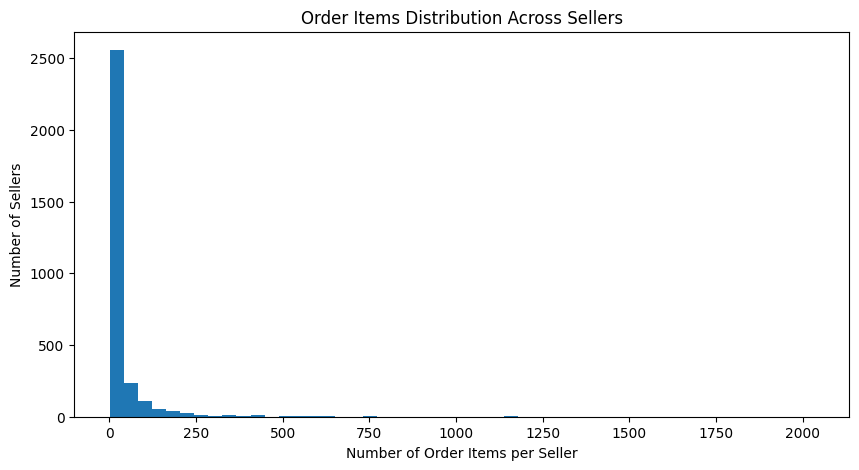

In [65]:
plt.figure(figsize=(10, 5))
plt.hist(Most_seller, bins=50)

plt.title('Order Items Distribution Across Sellers')
plt.xlabel('Number of Order Items per Seller')
plt.ylabel('Number of Sellers')

plt.show()

In [68]:
df['product_id'].nunique()

32951

In [69]:
df.groupby('product_id')['order_item_id'].count().sort_values(ascending=False)

product_id
aca2eb7d00ea1a7b8ebd4e68314663af    527
99a4788cb24856965c36a24e339b6058    488
422879e10f46682990de24d770e7f83d    484
389d119b48cf3043d311335e499d9c6b    392
368c6c730842d78016ad823897a372db    388
                                   ... 
ffd7628b0b0b98ebc549e8e4c54a59af      1
ffd63ee42a5c8cc5a15a1c8e2aa50011      1
002959d7a0b0990fe2d69988affcbc80      1
002552c0663708129c0019cc97552d7d      1
0021a87d4997a48b6cef1665602be0f5      1
Name: order_item_id, Length: 32951, dtype: int64

In [70]:
Most_product = df.groupby('product_id')['order_item_id'].count().sort_values(ascending=False) 

Most_product.head(10)

product_id
aca2eb7d00ea1a7b8ebd4e68314663af    527
99a4788cb24856965c36a24e339b6058    488
422879e10f46682990de24d770e7f83d    484
389d119b48cf3043d311335e499d9c6b    392
368c6c730842d78016ad823897a372db    388
53759a2ecddad2bb87a079a1f1519f73    373
d1c427060a0f73f6b889a5c7c61f2ac4    343
53b36df67ebb7c41585e8d54d6772e08    323
154e7e31ebfa092203795c972e5804a6    281
3dd2a17168ec895c781a9191c1e95ad7    274
Name: order_item_id, dtype: int64

In [71]:
Most_product.describe()

count    32951.000000
mean         3.418713
std         10.619709
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        527.000000
Name: order_item_id, dtype: float64

### Product Distribution Visualization

The histogram shows a highly right-skewed distribution.

Most products appear in a small number of order items, while a small number of products appear much more frequently.

This is consistent with the mean (3.42) being greater than the median (1), indicating an uneven distribution of product appearances.

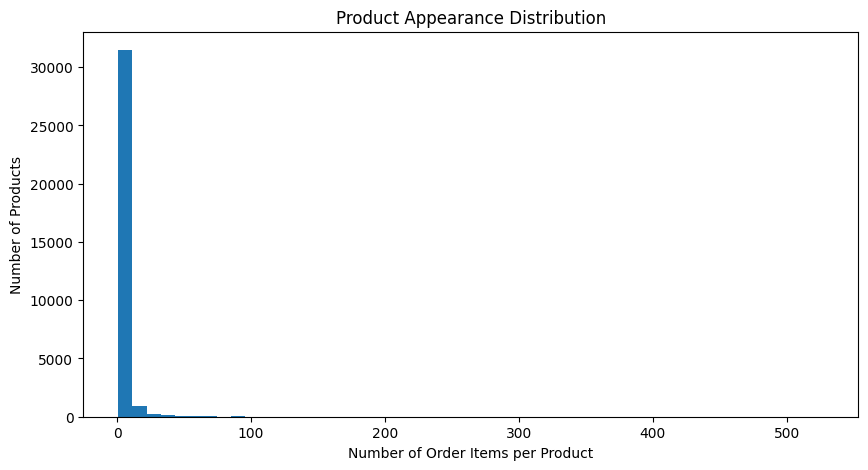

In [73]:
plt.figure(figsize=(10, 5))
plt.hist(Most_product, bins=50)

plt.title('Product Appearance Distribution')
plt.xlabel('Number of Order Items per Product')
plt.ylabel('Number of Products')

plt.show()

## Final Insights & Conclusion

### Key Findings

1. The dataset contains **112,650 order item records** representing **99,441 unique orders**.
2. The dataset includes **32,951 unique products** and **3,095 unique sellers**.
3. No missing values or fully duplicated records were detected.
4. Most orders contain a single order item, while a smaller number of orders contain multiple items.
5. Some products appear multiple times within the same order, affecting **6,968 distinct orders**.
6. Seller activity is highly right-skewed, indicating that some sellers account for considerably more order items than others.
7. Product appearances are also highly right-skewed, with a small number of products appearing much more frequently.
8. Both price and freight value distributions are right-skewed, with some unusually high values identified using the IQR method.

### Conclusion

The analysis provides an overview of order composition, product popularity, seller activity, and pricing patterns in the Olist order items dataset.

The dataset contains no missing or fully duplicated records. However, several statistical outliers and repeated product occurrences were identified. These observations should be investigated in their business context before treating them as data quality issues or removing them.

Overall, the dataset provides useful insights into customer purchasing patterns, product demand, seller activity, and shipping costs.